# 3. Saved results: S/M/L QUBO comparison

Compare **classical slack**, **classical unbalanced**, **quantum slack**, and
**quantum unbalanced**, plus **classical/quantum variable reduction**, using outputs from previous runs.

**This notebook does not run any solver, emulator, pulse calibration, reference
search, or routing algorithm, and does not overwrite benchmark outputs.**
It reads saved manifests, references and raw counts, then decodes those counts
and computes descriptive statistics for display. Optional CVRP gaps are read
only from matching saved evaluation caches.


## Select saved run directories

Each tier has its own output directory. Select the folders actually used by the
classical and quantum notebooks. Paths may be repository-relative or absolute.
`seed` selects an already-saved sampling seed; changing it does not run sampling.

The saved manifest defines the instances being compared, even if the input
JSON has changed since the run. No current seeds file is loaded. The selected
fresh S and M folders each contain three instances. Compare solvers
**within each tier**, not absolute
clustering costs between S and M.

Missing solver files are shown as **Not saved**, never replaced by new runs.
To include future M unbalanced runs, point `SAVED_OUTPUTS["M"]` at their matching
M benchmark folder after running the optimization notebooks separately.


In [2]:
SAVED_OUTPUTS = {
    "S": "track_a/outputs/seeds_s_comparison_full",
    "M": "track_a/outputs/seeds_m_comparison_full",
 "L": "track_a/outputs/seeds_l_comparison_full",
}
seed = 0

CLUSTER_INSTANCES = None  # Show every saved S and M instance.
VISUALS_DIRECTORY = "track_a/outputs/result_visuals"


In [3]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "track_a" / "common" / "comparison.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from track_a.common.comparison import (
    saved_comparisons, comparison_summary, plot_saved_comparisons,
)

runs = saved_comparisons(SAVED_OUTPUTS, seed)
summary = comparison_summary(runs)
print("Reading existing seed", seed, "outputs only. No solver or emulator is executed.")
visuals_output = Path(VISUALS_DIRECTORY).expanduser()
if not visuals_output.is_absolute():
    visuals_output = root / visuals_output
visuals_output.mkdir(parents=True, exist_ok=True)
exported_visuals = []


Reading existing seed 0 outputs only. No solver or emulator is executed.


## 1. Evidence coverage

Check coverage before comparing quality. **Completed** means sampling finished,
not that a feasible solution was found. Failed/resource-limited runs and missing
files are counted separately and excluded from shot-probability denominators.
The sources below are explicit: data from incompatible datasets are not merged.


In [4]:
display(runs.groupby(["tier", "source_directory"], sort=False).agg(
    instances=("instance_id", "nunique"),
    expected_qubo_runs=("method", "size"),
).reset_index())
display(summary[["tier", "solver", "expected_runs", "completed_runs", "failed_runs",
                 "missing_runs", "feasible_result_runs"]])


,tier,source_directory,instances,expected_qubo_runs
0,S,/workspaces/duquantum_hack_2026/track_a/output...,3,18
1,M,/workspaces/duquantum_hack_2026/track_a/output...,3,18
2,L,/workspaces/duquantum_hack_2026/track_a/output...,3,18


,tier,solver,expected_runs,completed_runs,failed_runs,missing_runs,feasible_result_runs
0,S,Classical slack,3,3,0,0,3
1,S,Classical unbalanced,3,3,0,0,3
2,S,Classical variable reduction,3,3,0,0,3
3,S,Quantum slack,3,3,0,0,3
4,S,Quantum unbalanced,3,3,0,0,3
5,S,Quantum variable reduction,3,3,0,0,3
6,M,Classical slack,3,3,0,0,0
7,M,Classical unbalanced,3,3,0,0,3
8,M,Classical variable reduction,3,3,0,0,3
9,M,Quantum slack,3,3,0,0,0


## 2. Quality summary and charts

- **Feasible shots:** original one-hot assignment and capacity constraints hold.
- **Optimal hits:** feasible shots within 0.1% of the saved exact clustering
  reference. Both rates use **all completed raw shots**, not just feasible ones.
- **Best gap:** `100 * (best feasible cost - reference) / reference`. Lower is
  better; 0% means at least one optimal sample, not that all shots were optimal.
- **Mean best gap** averages only runs with a feasible result. Always read it
  alongside coverage; failures and undefined gaps are not treated as zeros.

Bars show shot probabilities. Dots show each instance's best feasible gap;
black diamonds show the mean. Missing/failed-only methods are annotated rather
than plotted as successful zero-gap results. There are no speedup claims.


,tier,solver,actual_shots,feasibility_percent,optimal_hit_percent,mean_best_gap_percent,worst_best_gap_percent,median_solver_seconds
0,S,Classical slack,768,20.96,5.60,0.00,0.00,0.027
1,S,Classical unbalanced,768,89.45,27.21,0.00,0.00,0.028
2,S,Classical variable reduction,768,87.37,23.31,0.00,0.00,0.040
3,S,Quantum slack,768,2.86,0.39,1.26,3.77,14.141
4,S,Quantum unbalanced,768,1.30,0.91,0.00,0.00,10.348
5,S,Quantum variable reduction,768,7.55,1.82,0.00,0.00,22.443
6,M,Classical slack,768,0.00,0.00,N/A,N/A,0.030
7,M,Classical unbalanced,768,59.64,0.39,10.91,32.72,0.032
8,M,Classical variable reduction,768,27.86,0.00,26.08,37.25,0.032
9,M,Quantum slack,768,0.00,0.00,N/A,N/A,55.295


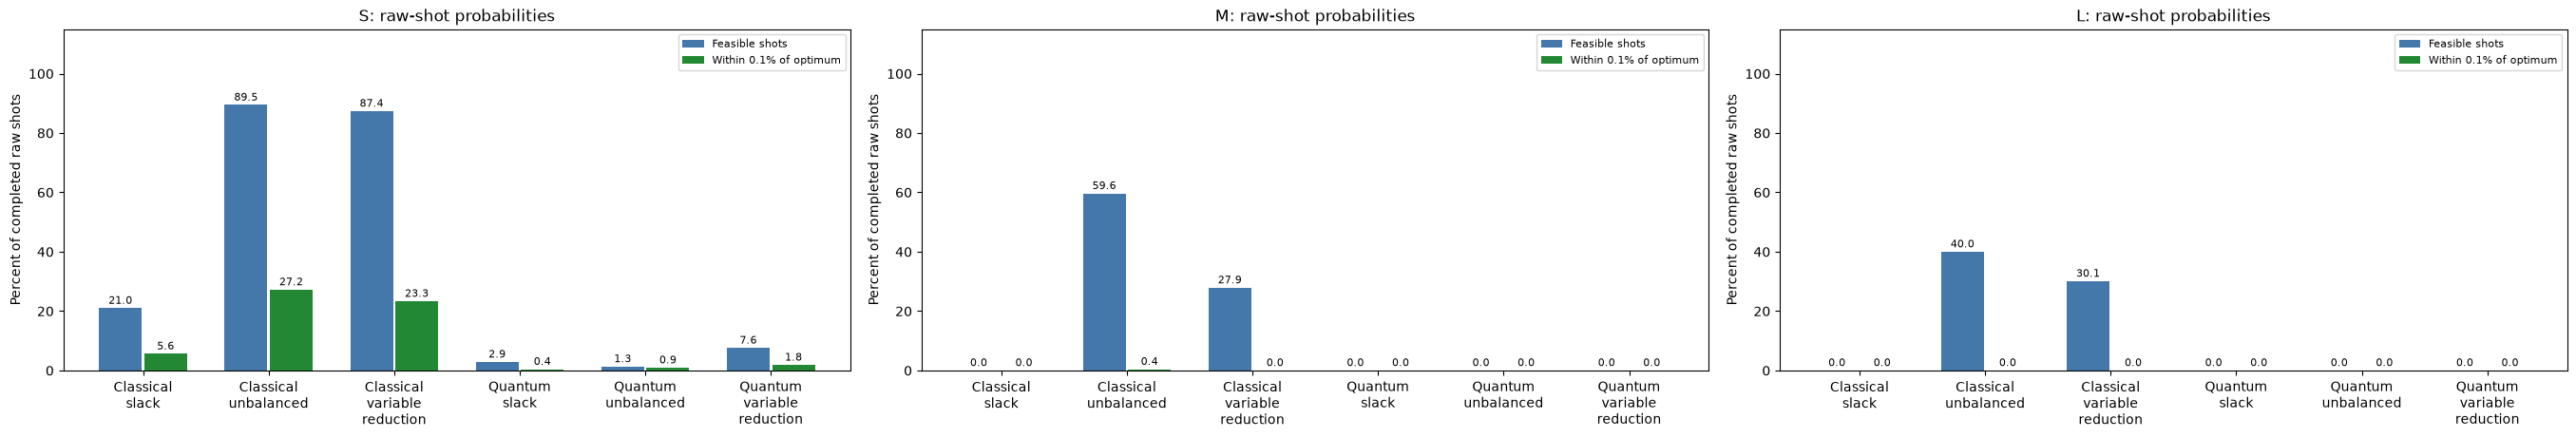

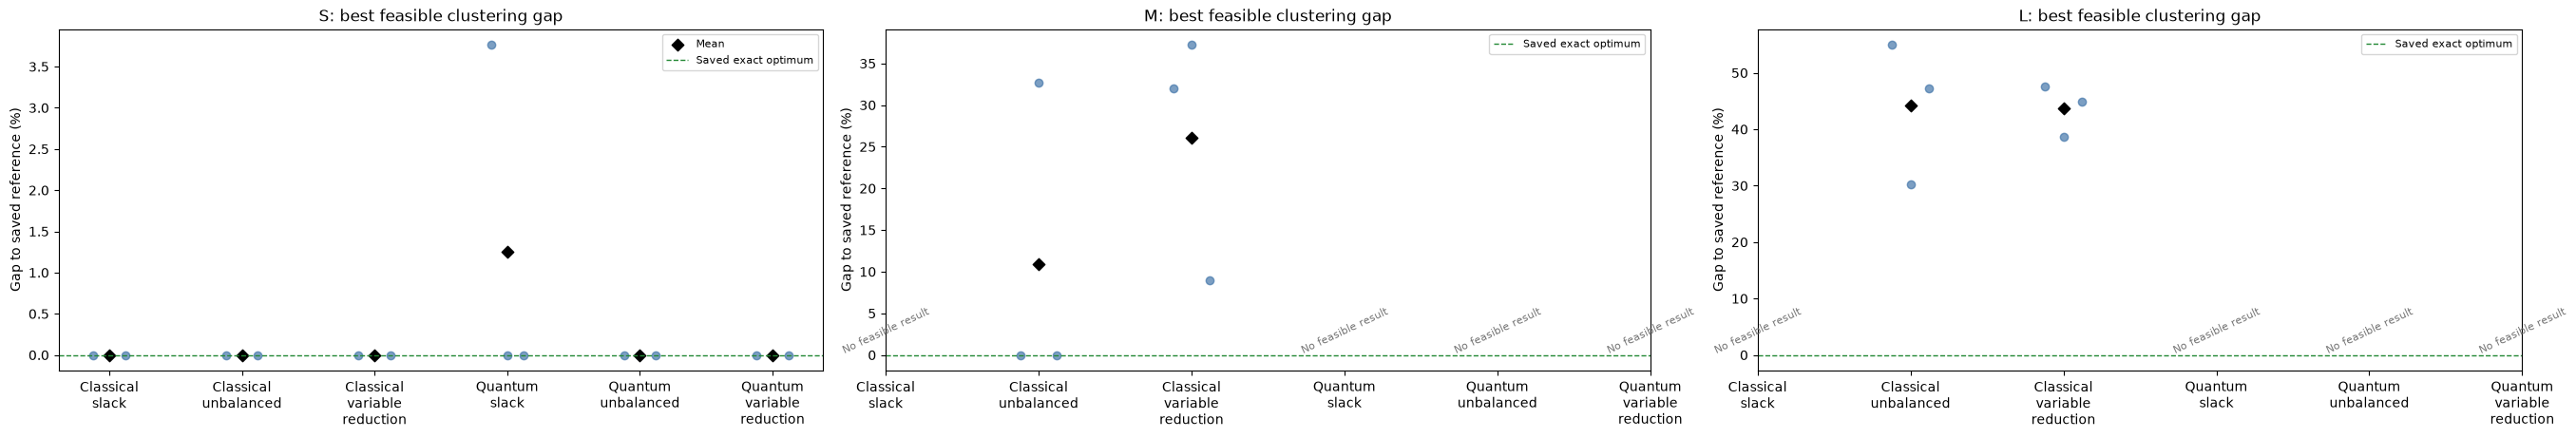

In [5]:
display(summary[["tier", "solver", "actual_shots", "feasibility_percent",
                 "optimal_hit_percent", "mean_best_gap_percent", "worst_best_gap_percent",
                 "median_solver_seconds"]].style.format({
    "feasibility_percent": "{:.2f}", "optimal_hit_percent": "{:.2f}",
    "mean_best_gap_percent": "{:.2f}", "worst_best_gap_percent": "{:.2f}",
    "median_solver_seconds": "{:.3f}",
}, na_rep="N/A"))
for figure in plot_saved_comparisons(runs, summary):
    image_path = visuals_output / f"{figure.get_label()}.png"
    figure.savefig(image_path, dpi=200, bbox_inches="tight")
    exported_visuals.append(image_path)
    display(figure)
    plt.close(figure)


### How to read the comparison

A taller green bar means a higher chance of obtaining a near-optimal feasible
answer from a raw shot. A tall blue bar with a short green bar means feasibility
is common but good clustering is not. Low gap dots indicate good **best-case**
quality; they do not imply a high success probability.

Unbalanced penalization reduces bits, but can change the preferred grouping
and has no general feasibility guarantee. Quantum embedding and global drive
are approximate. Better classical target-QUBO results do not establish better
quantum results. Sampling noise and the differing numbers of saved instances
also limit conclusions.


`variable_reduction` follows the photographed residual `load/Q - 1 - b`,
with one binary slack per vehicle (10 S bits, 33 M bits, 64 L bits). Its physical
auxiliary is complemented (`b=1-z`) to allow repulsive embedding.
It is not slack-free and can favor overload; original feasibility
checks remain unchanged. Compare all three formulations by feasible
cost and raw-shot probabilities, not their different target energies.

**L-tier context:** slack/unbalanced/variable-reduction use 80/60/64 atoms.
All L quantum runs use `emu-mps`, not QPU. L references are exact
clustering-only subset-DP optima. Its unbalanced weights (0.75, 0.02) are
untuned starting values transferred from M, not an L-specific optimum.
Timeouts and missing feasible assignments remain explicit; they are not
replaced with classical solutions. The same recorded sampling/resource
settings are used, without claiming MPS convergence.


## 3. Direct per-instance cost comparison

Only feasible original clustering costs are shown. `N/A` means no usable saved
answer, not zero cost. The next table retains the exact outcome and assignment
for each method so missing data, no feasible samples, and timeouts are distinct.


In [6]:
costs = runs.pivot(index=["tier", "instance_id"], columns="solver", values="model_cost")
reference_costs = runs.groupby(["tier", "instance_id"], sort=False)["reference_cost"].first()
display(costs.join(reference_costs.rename("Saved exact reference")).style.format("{:.3f}", na_rep="N/A"))
display(runs[["tier", "instance_id", "solver", "status", "outcome", "feasible_shots",
              "actual_shots", "model_cost", "best_model_gap",
              "customer_labels", "canonical_assignment_bits"]])


,tier,instance_id,solver,status,outcome,feasible_shots,actual_shots,model_cost,best_model_gap,customer_labels,canonical_assignment_bits
0,S,s-0,Classical slack,completed,Feasible sample found,55.0,256.0,80.886853,0.000000,"[0, 1, 1, 0]",10010110
1,S,s-0,Classical unbalanced,completed,Feasible sample found,219.0,256.0,80.886853,0.000000,"[0, 1, 1, 0]",10010110
2,S,s-0,Classical variable reduction,completed,Feasible sample found,220.0,256.0,80.886853,0.000000,"[0, 1, 1, 0]",10010110
3,S,s-0,Quantum slack,completed,Feasible sample found,7.0,256.0,83.933395,3.766423,"[0, 0, 1, 1]",10100101
4,S,s-0,Quantum unbalanced,completed,Feasible sample found,4.0,256.0,80.886853,0.000000,"[0, 1, 1, 0]",10010110
5,S,s-0,Quantum variable reduction,completed,Feasible sample found,14.0,256.0,80.886853,0.000000,"[0, 1, 1, 0]",10010110
6,S,s-1,Classical slack,completed,Feasible sample found,51.0,256.0,80.886853,0.000000,"[0, 1, 1, 0]",10010110
7,S,s-1,Classical unbalanced,completed,Feasible sample found,256.0,256.0,80.886853,0.000000,"[0, 1, 1, 0]",10010110
8,S,s-1,Classical variable reduction,completed,Feasible sample found,232.0,256.0,80.886853,0.000000,"[0, 1, 1, 0]",10010110
9,S,s-1,Quantum slack,completed,Feasible sample found,5.0,256.0,80.886853,0.000000,"[0, 1, 1, 0]",10010110


### Chosen clusters on the saved customer coordinates

Each map compares the saved exact reference with the six QUBO methods'
**best feasible saved samples**. Colors identify canonical vehicle groups;
labels show customer IDs and demands, and titles show vehicle loads/capacity.
Gray points mean no feasible result is available, not an assigned cluster.
No routes or new solutions are computed. Change `CLUSTER_INSTANCES` in the
parameter cell to select instances, or set it to `None` to show all saved instances.


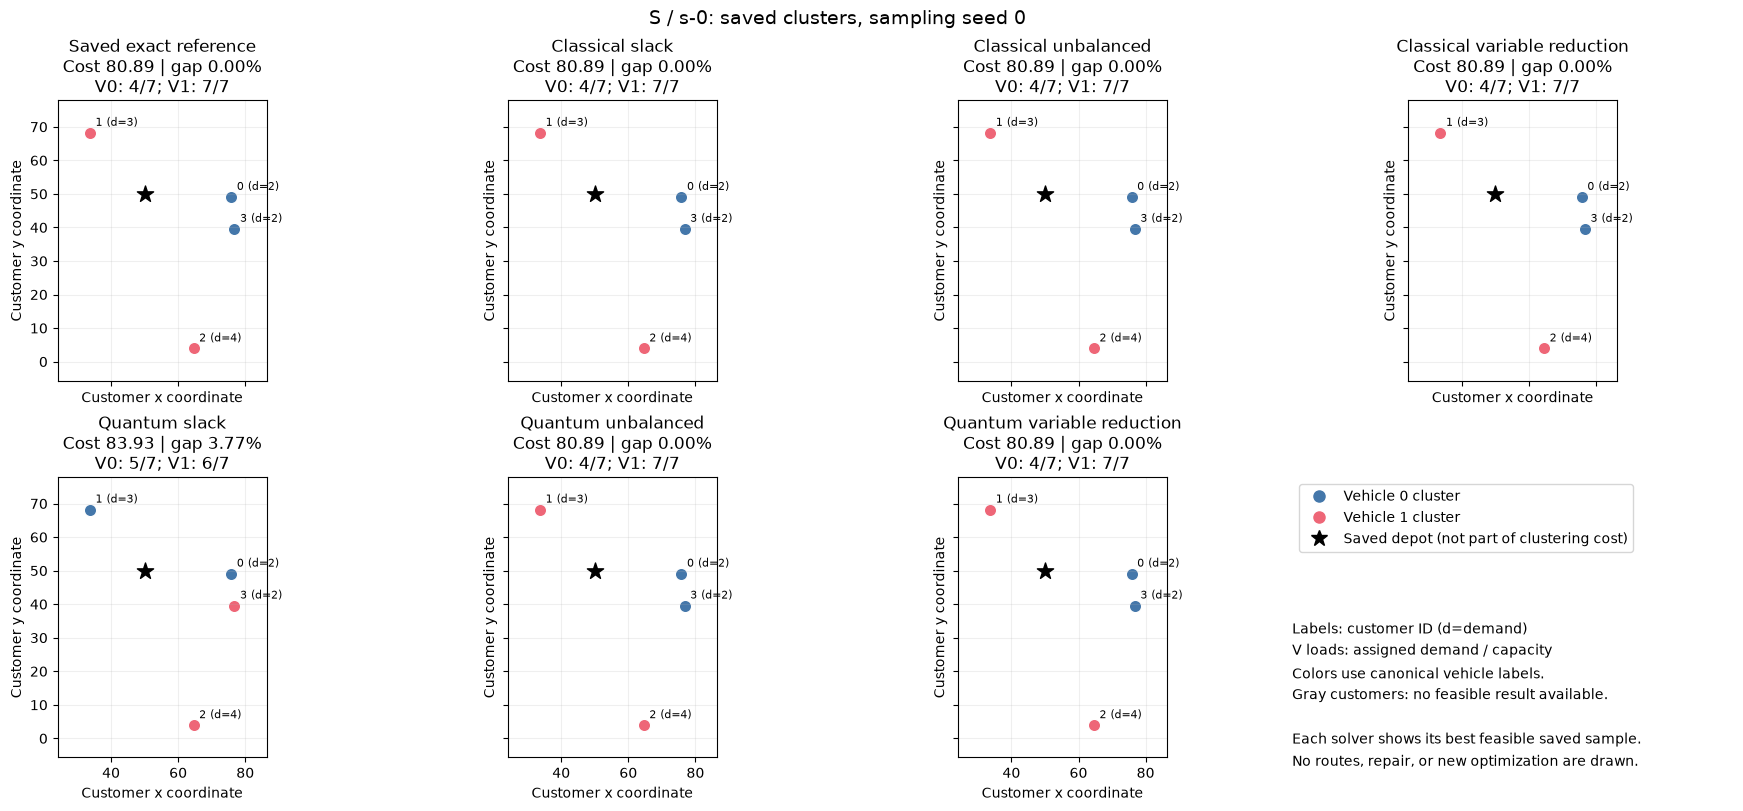

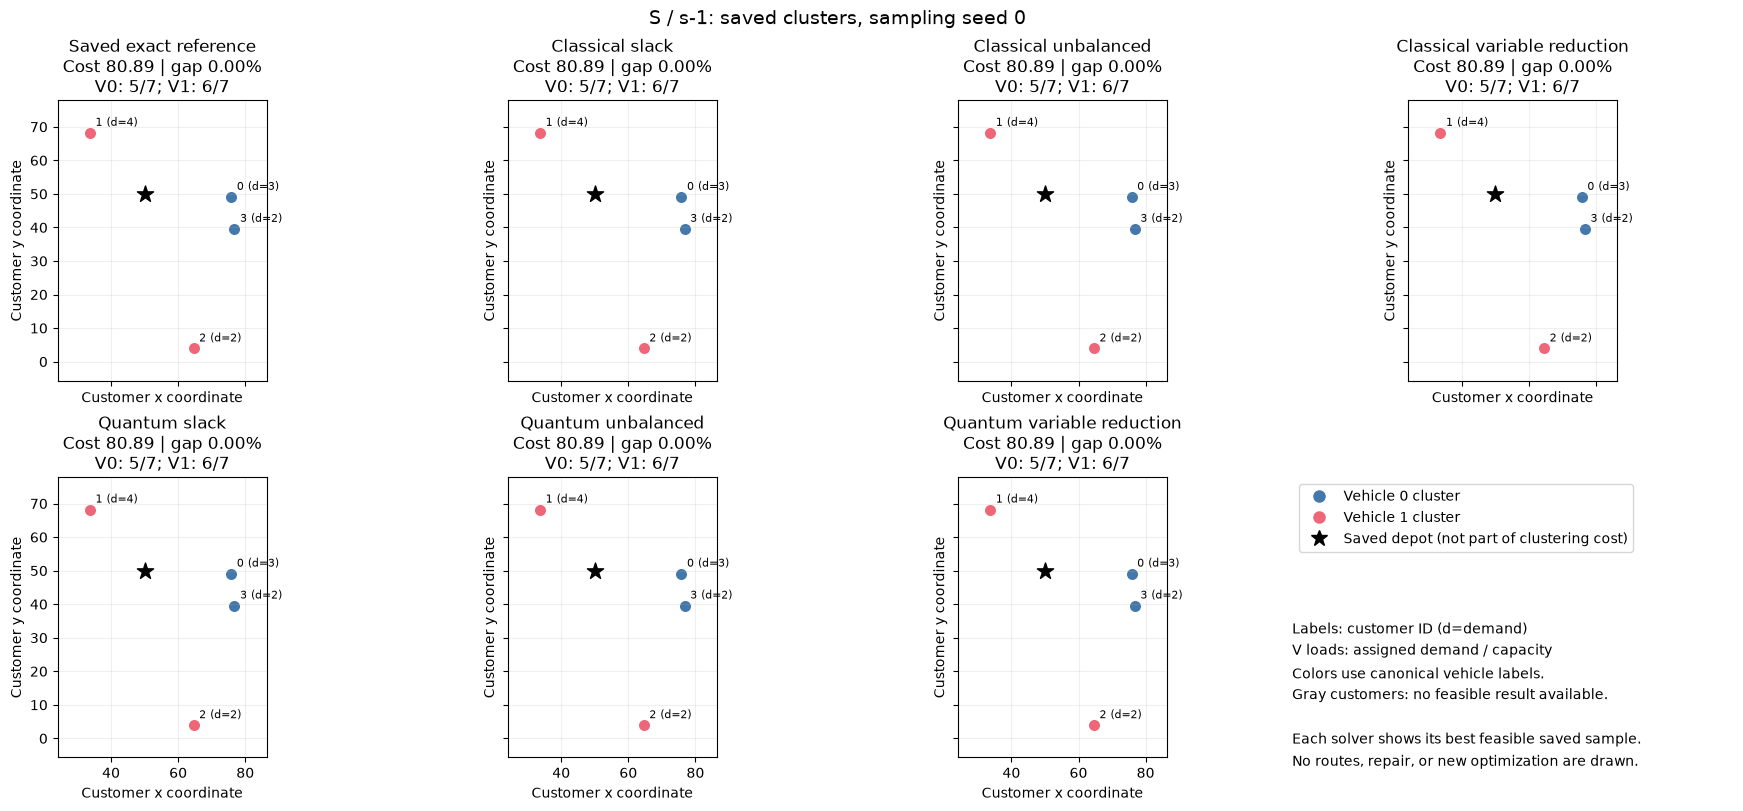

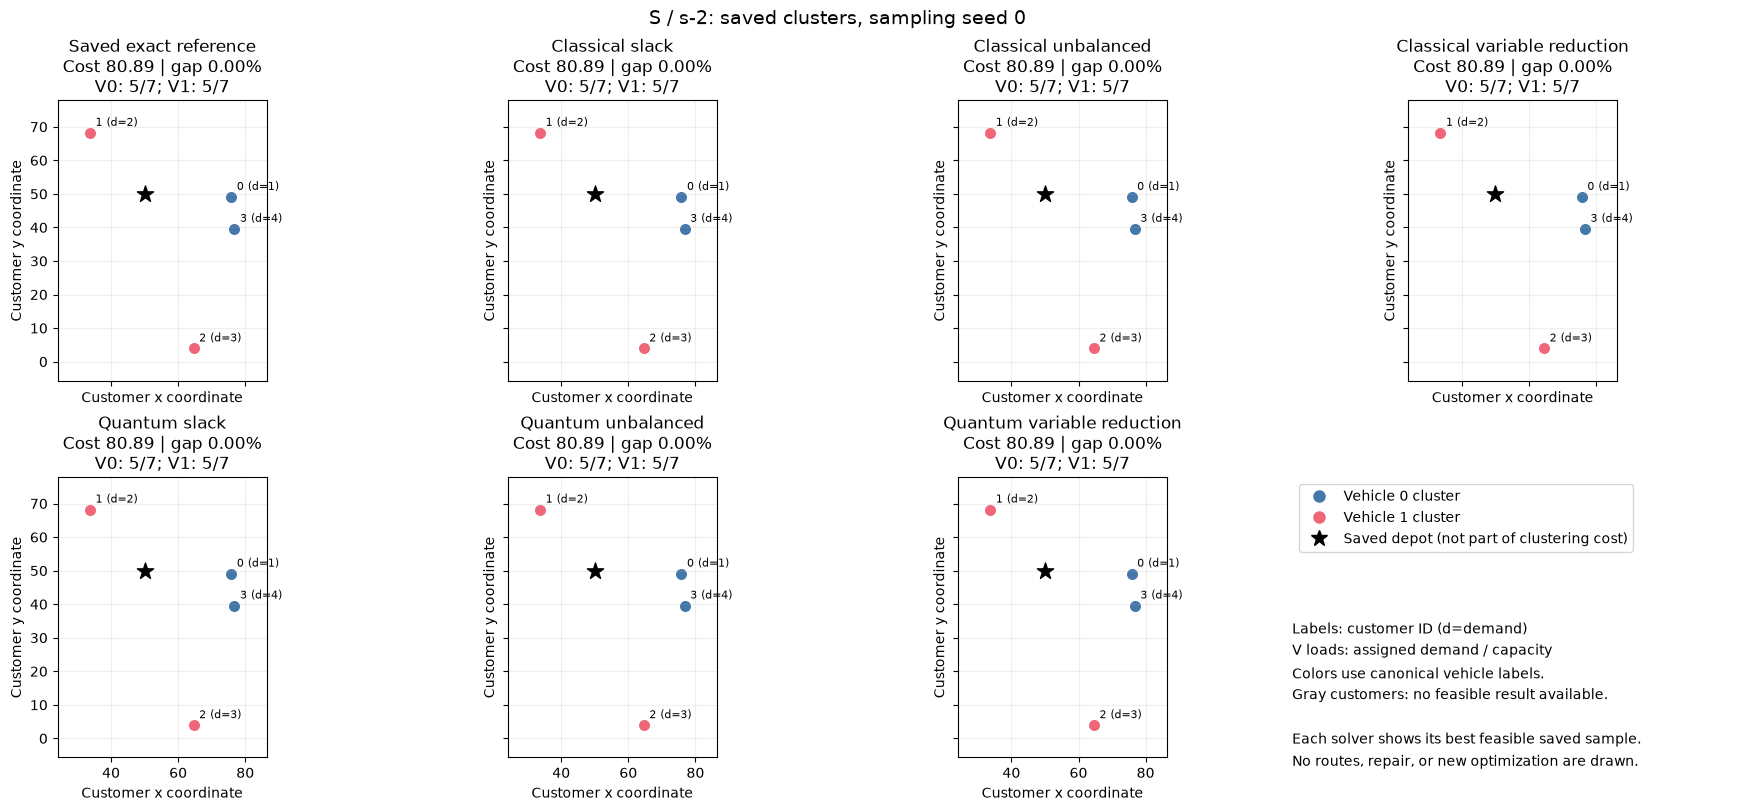

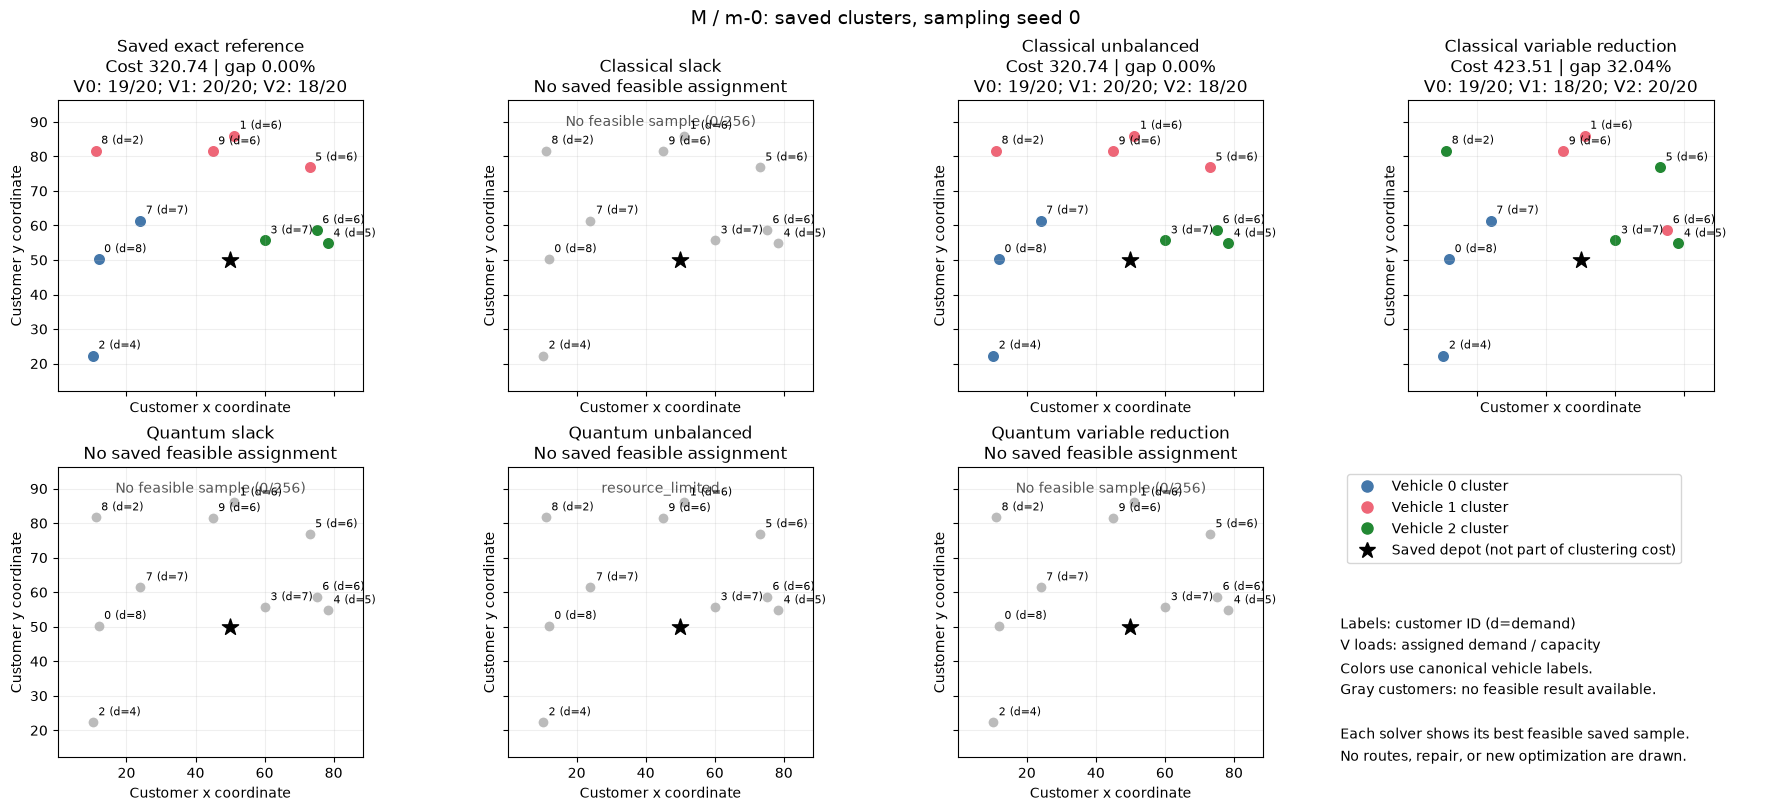

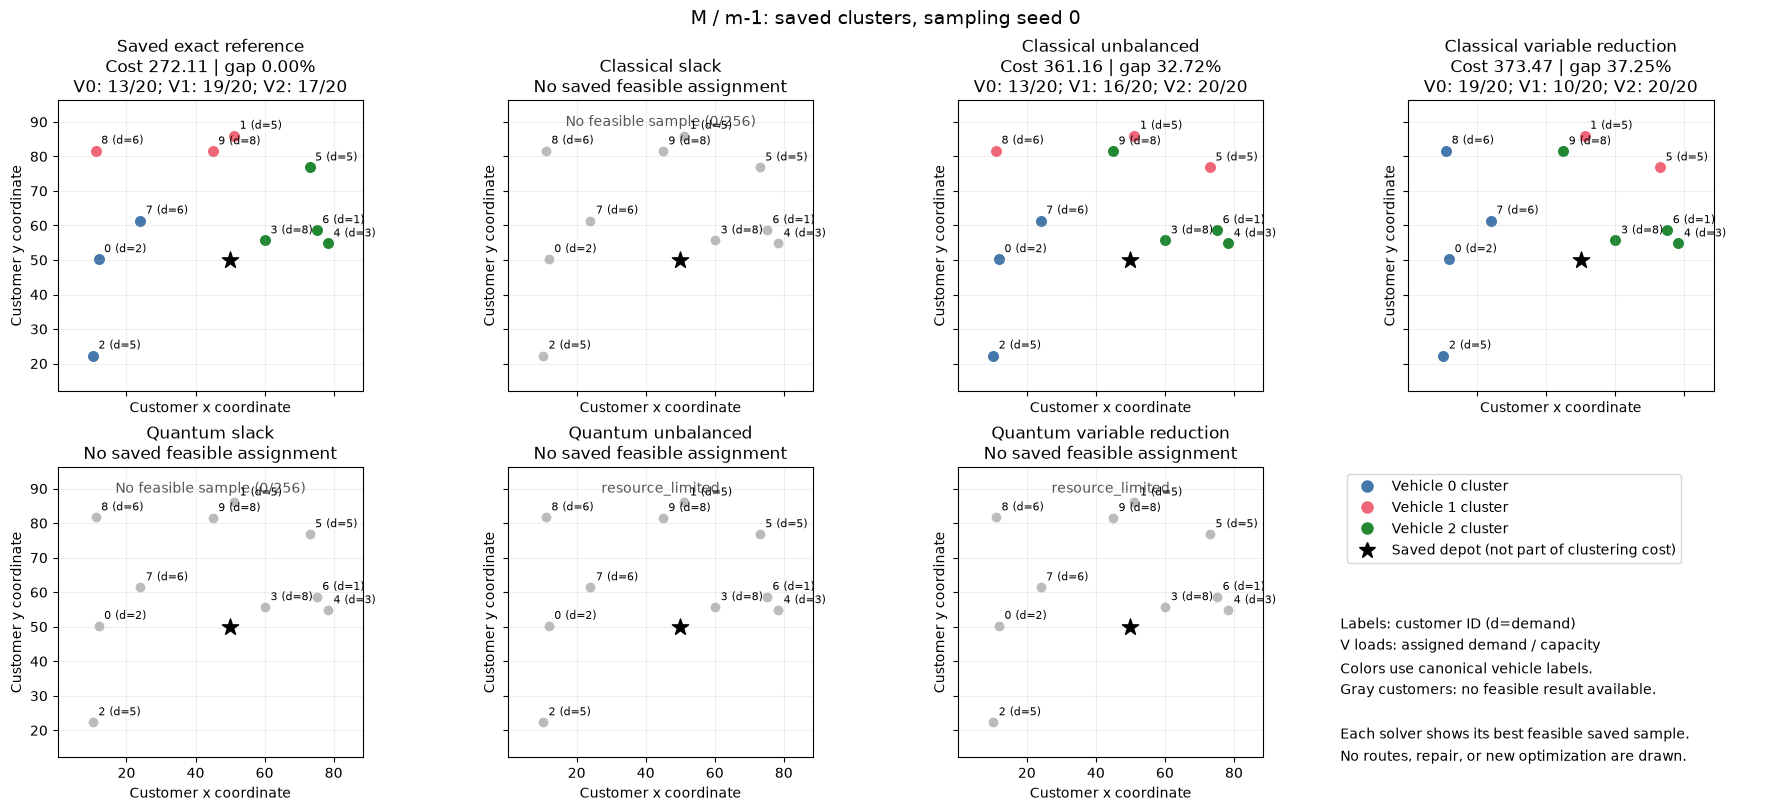

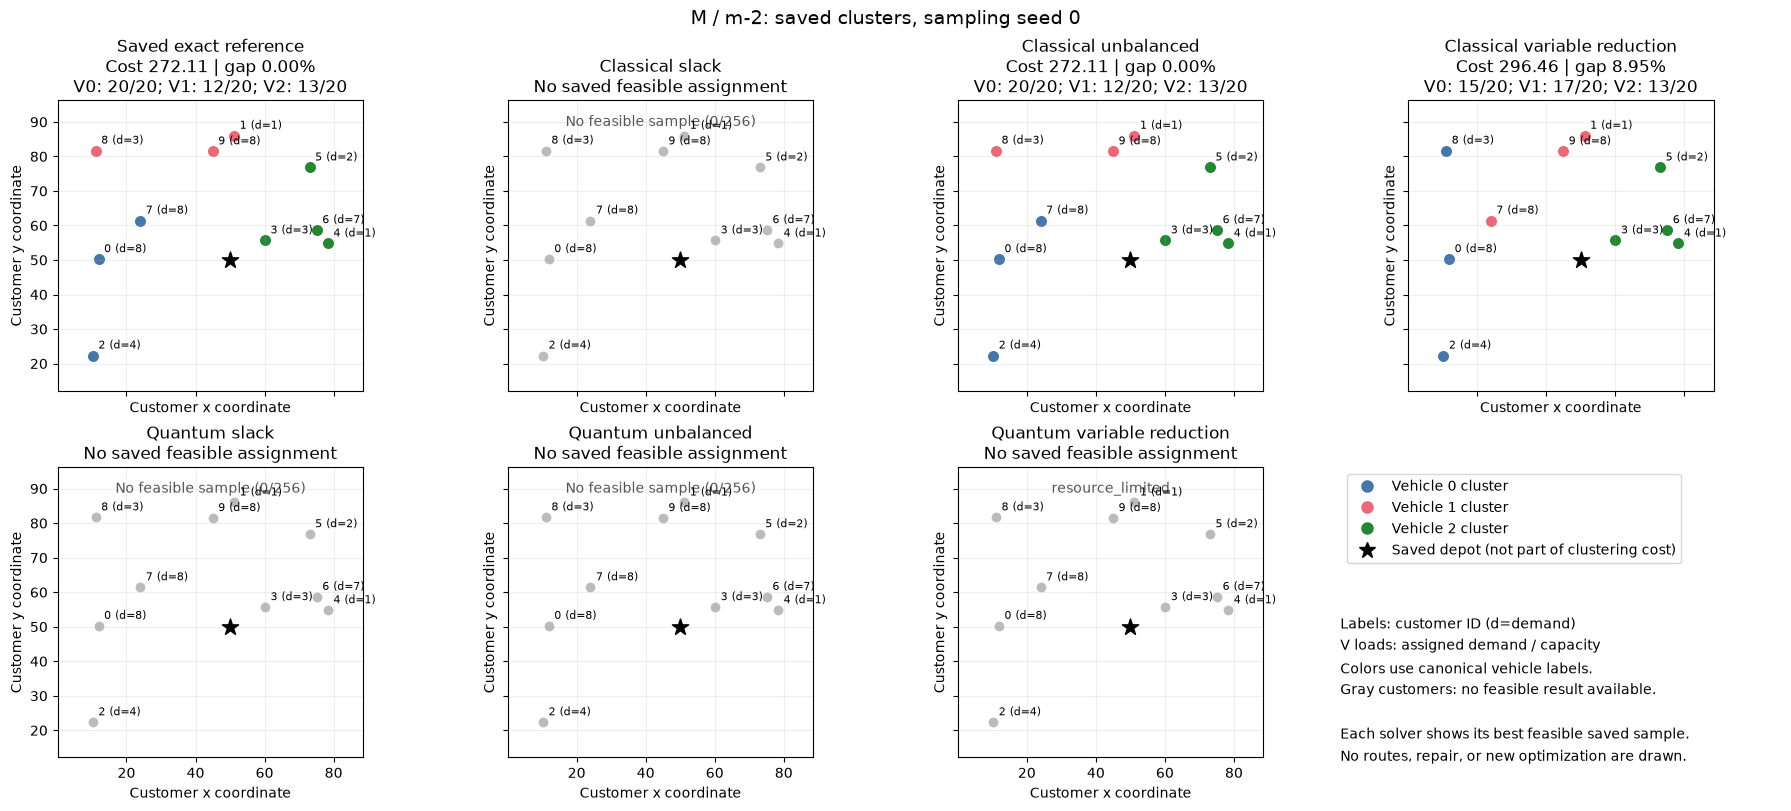

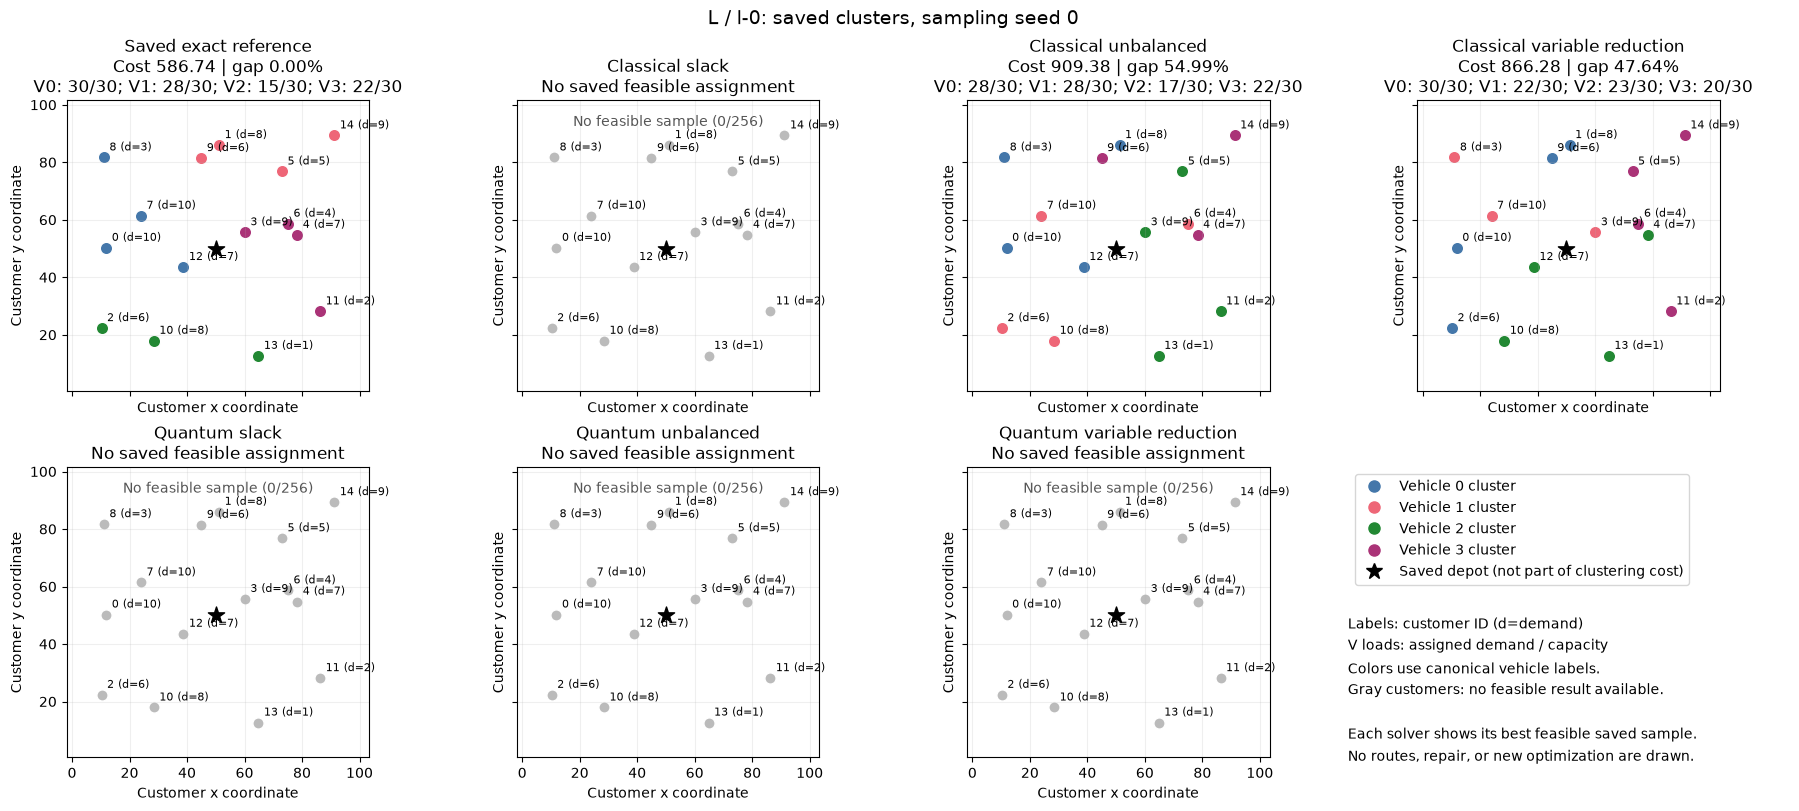

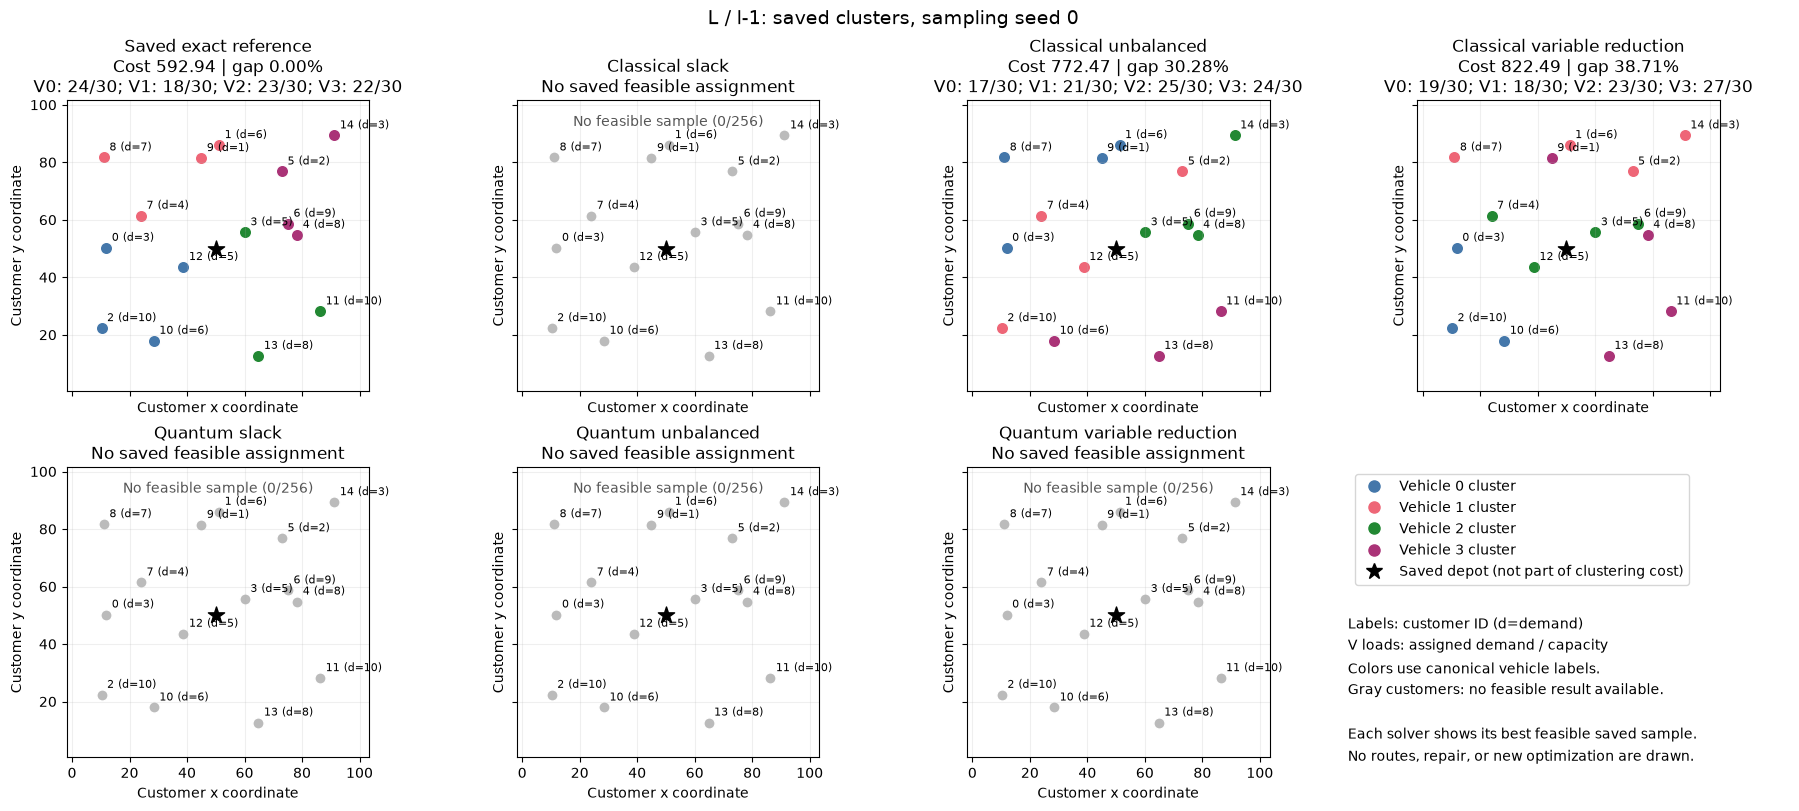

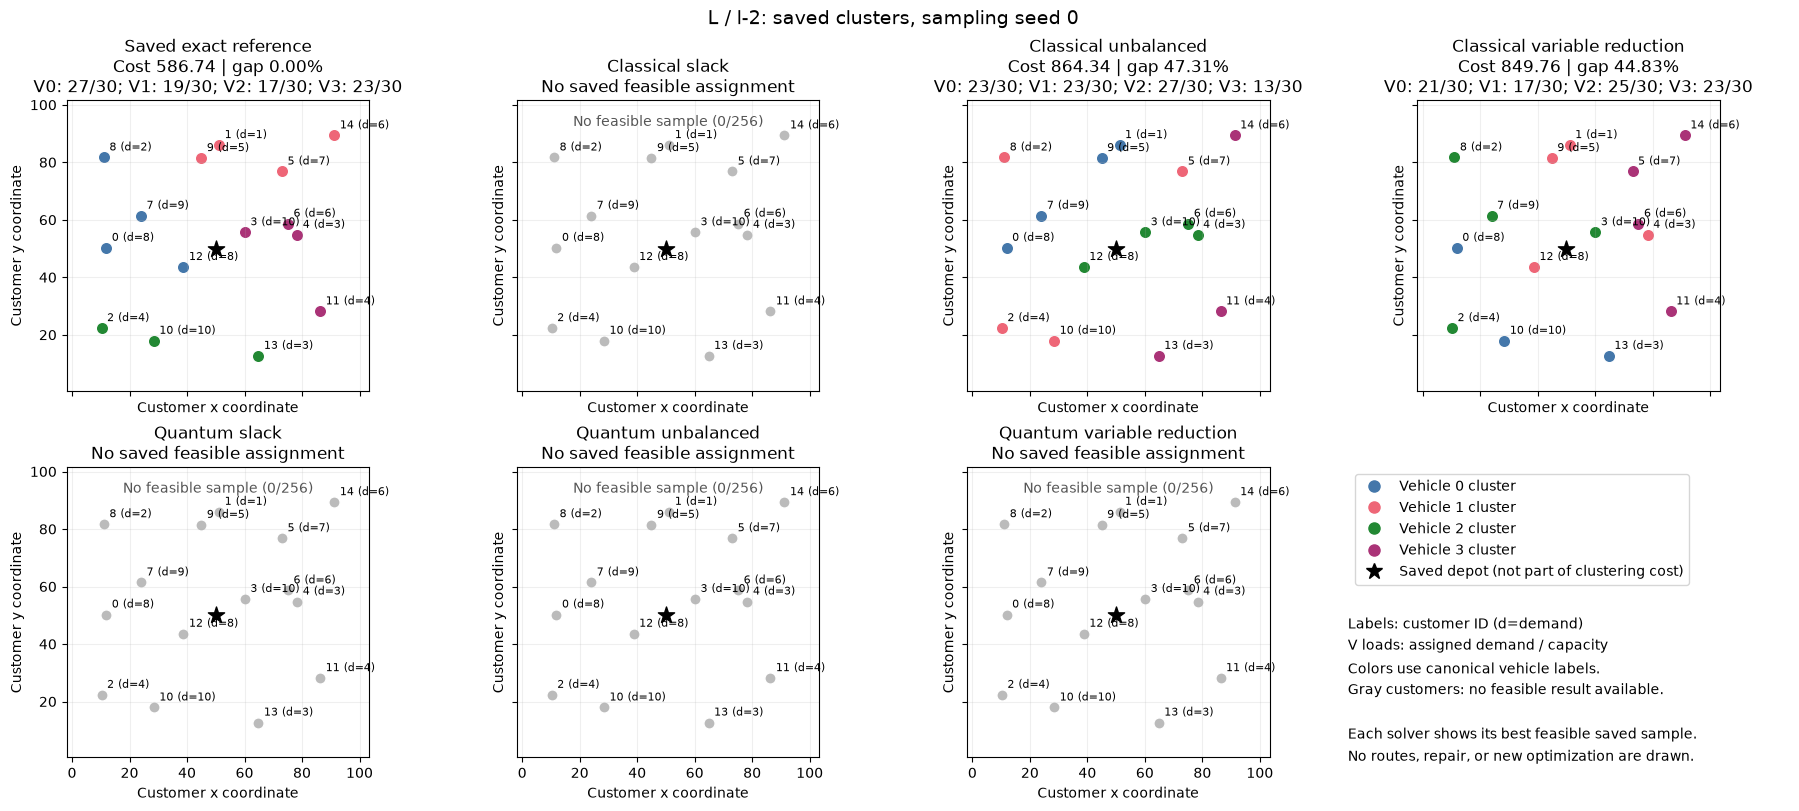

Exported 11 PNG visuals to /workspaces/duquantum_hack_2026/track_a/outputs/result_visuals
shot_probabilities.png
best_clustering_gaps.png
clusters_s-0.png
clusters_s-1.png
clusters_s-2.png
clusters_m-0.png
clusters_m-1.png
clusters_m-2.png
clusters_l-0.png
clusters_l-1.png
clusters_l-2.png


In [7]:
from track_a.common.comparison import plot_saved_clusters

for figure in plot_saved_clusters(runs, CLUSTER_INSTANCES):
    image_path = visuals_output / f"{figure.get_label()}.png"
    figure.savefig(image_path, dpi=200, bbox_inches="tight")
    exported_visuals.append(image_path)
    display(figure)
    plt.close(figure)
print(f"Exported {len(exported_visuals)} PNG visuals to {visuals_output}")
for image_path in exported_visuals:
    print(image_path.name)


## 4. Saved configurations and limitations

These are the **weights recorded in each old run**, not today's presets.
Editing `inputs/unbalanced_penalties.json` does not change previous results.
Raw bit counts include slack where applicable. Classical runtime is saved
annealing time; quantum runtime is saved embedding plus emulation time,
excluding calibration and offline references. These are not equivalent units
of computational work, so runtime alone is not a fair speedup measure.


In [8]:
display(runs[["tier", "instance_id", "solver", "seed", "bits", "lambda1", "lambda2",
              "assignment_penalty", "backend", "solver_seconds", "configuration_id"]])
unavailable = runs[(runs["status"] != "completed") | runs["feasible_shots"].eq(0)]
if len(unavailable):
    print("Missing, failed, or no-feasible-result evidence:")
    display(unavailable[["tier", "instance_id", "solver", "status", "outcome", "error"]])
else:
    print("Every selected saved QUBO run has at least one feasible sample.")

photo_configurations = runs[runs["formulation"] == "variable_reduction"]
display(photo_configurations[["tier", "instance_id", "solver", "bits",
                             "alpha", "beta", "auxiliary_mapping"]])


,tier,instance_id,solver,seed,bits,lambda1,lambda2,assignment_penalty,backend,solver_seconds,configuration_id
0,S,s-0,Classical slack,0,14,NaN,NaN,2.508127,NaN,0.026670,a7030aae2f83fe84
1,S,s-0,Classical unbalanced,0,8,0.20,0.01,2.508127,NaN,0.028997,298cf055c0e2ce71
2,S,s-0,Classical variable reduction,0,10,NaN,NaN,2.508127,NaN,0.039112,5d8ba5c5904f988b
3,S,s-0,Quantum slack,0,14,NaN,NaN,2.508127,emu-sv,15.870799,9a47b623e00ea015
4,S,s-0,Quantum unbalanced,0,8,0.20,0.01,2.508127,emu-sv,10.752829,616d4c597ae3e885
5,S,s-0,Quantum variable reduction,0,10,NaN,NaN,2.508127,emu-sv,24.618560,51eff1503953099c
6,S,s-1,Classical slack,0,14,NaN,NaN,2.176912,NaN,0.025444,72668eb6ca284420
7,S,s-1,Classical unbalanced,0,8,0.20,0.01,2.176912,NaN,0.027850,839d6f3ab413aaff
8,S,s-1,Classical variable reduction,0,10,NaN,NaN,2.176912,NaN,0.039978,faf0380b2bc2a2f2
9,S,s-1,Quantum slack,0,14,NaN,NaN,2.176912,emu-sv,11.816963,54dd7bd85d7231d9


Missing, failed, or no-feasible-result evidence:


,tier,instance_id,solver,status,outcome,error
18,M,m-0,Classical slack,completed,No feasible sample (0/256),NaN
21,M,m-0,Quantum slack,completed,No feasible sample (0/256),NaN
22,M,m-0,Quantum unbalanced,resource_limited,resource_limited,Command '['/workspaces/duquantum_hack_2026/.ve...
23,M,m-0,Quantum variable reduction,completed,No feasible sample (0/256),NaN
24,M,m-1,Classical slack,completed,No feasible sample (0/256),NaN
27,M,m-1,Quantum slack,completed,No feasible sample (0/256),NaN
28,M,m-1,Quantum unbalanced,resource_limited,resource_limited,Command '['/workspaces/duquantum_hack_2026/.ve...
29,M,m-1,Quantum variable reduction,resource_limited,resource_limited,Command '['/workspaces/duquantum_hack_2026/.ve...
30,M,m-2,Classical slack,completed,No feasible sample (0/256),NaN
33,M,m-2,Quantum slack,completed,No feasible sample (0/256),NaN


,tier,instance_id,solver,bits,alpha,beta,auxiliary_mapping
2,S,s-0,Classical variable reduction,10,2.508127,2.508127,b_k = 1 - z_k
5,S,s-0,Quantum variable reduction,10,2.508127,2.508127,b_k = 1 - z_k
8,S,s-1,Classical variable reduction,10,2.176912,2.176912,b_k = 1 - z_k
11,S,s-1,Quantum variable reduction,10,2.176912,2.176912,b_k = 1 - z_k
14,S,s-2,Classical variable reduction,10,3.301381,3.301381,b_k = 1 - z_k
17,S,s-2,Quantum variable reduction,10,3.301381,3.301381,b_k = 1 - z_k
20,M,m-0,Classical variable reduction,33,8.062849,8.062849,b_k = 1 - z_k
23,M,m-0,Quantum variable reduction,33,8.062849,8.062849,b_k = 1 - z_k
26,M,m-1,Classical variable reduction,33,6.223407,6.223407,b_k = 1 - z_k
29,M,m-1,Quantum variable reduction,33,6.223407,6.223407,b_k = 1 - z_k


## 5. Optional saved CVRP evaluation

Clustering and CVRP are different objectives. If an earlier evaluation saved
fixed-group routing gaps, display them below **only when the run and reference
hashes still match**. Missing or stale evaluations remain unavailable; this
notebook never computes tours or creates new routing references.
The detailed `runs` and `summary` DataFrames above remain available for inspection.

AI implementation assistance was used for this viewer; displayed measurements
come from saved local solver/emulator outputs, not generated performance claims.


In [9]:
cached_routes = runs[runs["saved_cvrp_gap"].notna()]
if len(cached_routes):
    display(cached_routes[["tier", "instance_id", "solver", "saved_cvrp_gap", "cvrp_evidence"]])
else:
    print("No matching saved CVRP gaps are available. No routing was run.")
display(runs.groupby(["tier", "solver", "cvrp_evidence"], sort=False).size().rename("runs").reset_index())


No matching saved CVRP gaps are available. No routing was run.


,tier,solver,cvrp_evidence,runs
0,S,Classical slack,Not saved,3
1,S,Classical unbalanced,Not saved,3
2,S,Classical variable reduction,Not saved,3
3,S,Quantum slack,Not saved,3
4,S,Quantum unbalanced,Not saved,3
5,S,Quantum variable reduction,Not saved,3
6,M,Classical slack,Not saved,3
7,M,Classical unbalanced,Not saved,3
8,M,Classical variable reduction,Not saved,3
9,M,Quantum slack,Not saved,3
